# 02 · Machine learning: TF-IDF + logistic regression (full re-run)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SheridanLu/detecting-the-detector/blob/main/notebooks/02_ml_logistic_regression.ipynb)

**Goal.** Train the simplest of our three detectors from scratch on the four training sets (arms A-D), measure how
often it wrongly flags human essays as AI, and check that the re-run gives the same numbers as the original run.

**This notebook really re-trains the model** (CPU only). Nothing is replayed here except the archived numbers used for
the comparison at the end.

| Mode | What runs | Expected time on a laptop CPU (Colab CPU is usually slower, roughly x2) | GPU |
|---|---|---|---|
| SMOKE | 4 arms x 1 seed, 200 + 200 training essays, scored on the Liang test set only | < 1 min | no |
| FAST (default) | 4 arms x 5 seeds, 8,000 training essays each (the setting of every headline number) | about 1.5-3 min | no |
| FULL | FAST + learning-curve runs (arms A/B with 1,000 and 2,000 essays per class, 5 seeds) | about 3-4 min | no |

The measured time is printed at the end of the notebook.

In [1]:
# --- Setup: find the repository (or download it on Colab) and install anything Colab does not have ---
import os, sys, time, pathlib, subprocess
T0 = time.time()
REPO_URL = "https://github.com/SheridanLu/detecting-the-detector"

def _is_repo(p):
    return (p / "ddlib" / "__init__.py").is_file() and (p / "data").is_dir()

def _locate_or_fetch():
    here = pathlib.Path.cwd().resolve()
    for p in [pathlib.Path(os.environ.get("DD_REPO", here)), here, *here.parents]:
        if _is_repo(p):
            return p                                   # mode 1: already inside the repo
    dest = pathlib.Path("/content" if os.path.isdir("/content") else here) / "detecting-the-detector"
    if not _is_repo(dest) and not dest.exists():       # mode 2: git clone (token optional, for a private repo)
        tok = os.environ.get("GH_TOKEN")
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN") or tok
        except Exception:
            pass
        url = REPO_URL.replace("https://", f"https://x-access-token:{tok}@") if tok else REPO_URL
        subprocess.run(["git", "clone", "--depth", "1", "-q", url, str(dest)], env=dict(os.environ, GIT_TERMINAL_PROMPT="0"))
        if tok and dest.exists():
            subprocess.run(["git", "-C", str(dest), "remote", "set-url", "origin", REPO_URL])   # token not kept on disk
    if _is_repo(dest):
        return dest
    return None                                        # mode 3 (zip upload) is handled by ddlib below

root = _locate_or_fetch()
if root is None:
    # Zip fallback: needs the small ddlib/paths.py helper, which we cannot import yet, so do it here.
    print("Could not find or clone the repository.\n"
          "Fix 1: add a Colab secret GH_TOKEN (key icon, left sidebar) with read access, allow notebook access, re-run.\n"
          f"Fix 2: download the repo as a zip ({REPO_URL} > Code > Download ZIP) and upload it when asked.")
    from google.colab import files
    import zipfile
    up = files.upload()
    zipfile.ZipFile(next(k for k in up if k.endswith(".zip"))).extractall("/content")
    root = next(p.parent.parent for p in pathlib.Path("/content").glob("*/ddlib/__init__.py") if _is_repo(p.parent.parent))
sys.path.insert(0, str(root))
os.chdir(root)                                         # all paths below are relative to the repo root

_req = [l.strip() for l in open("requirements-colab.txt") if l.strip() and not l.startswith("#")]
if _req:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_req], check=True)

from ddlib import get_repo
REPO = get_repo()
print("Python", sys.version.split()[0])

Repository found. Data folder present: True
Python 3.12.16


## Configuration

In [2]:
# --- CONFIG ---------------------------------------------------------------------------------------
# MODE = "SMOKE" (seconds; tiny version used for automated testing), "FAST" (default) or "FULL" (paper setting).
# Change the string below to switch. (The DD_MODE environment variable is only used by automated tests.)
MODE = os.environ.get("DD_MODE", "FAST").upper()
assert MODE in ("SMOKE", "FAST", "FULL"), MODE
SEEDS = [0] if MODE == "SMOKE" else [0, 1, 2, 3, 4]
SMOKE_N = 200                      # SMOKE only: essays per class used for training
RUNS = [(arm, s, 4000) for arm in "ABCD" for s in SEEDS]
if MODE == "FULL":
    RUNS += [(arm, s, n) for n in (1000, 2000) for arm in "AB" for s in SEEDS]
print("MODE =", MODE, "| runs to train:", len(RUNS))

MODE = FAST | runs to train: 20


## 1. The model
* **TF-IDF** turns an essay into a long list of numbers: one per word or word pair (bigram) in the vocabulary. A word
  gets a high number if it is frequent in this essay but rare across all essays.
* **Logistic regression** learns one weight per word/word pair and turns the weighted sum into a probability that
  the essay is AI-written. An essay is *flagged as AI* if that probability is at least 0.5.

Settings are copied from the original scripts `a40/train_lr.py` and `a40/followup_ml.py` (no tuning):

| setting | value |
|---|---|
| words used | single words and word pairs, `ngram_range=(1, 2)` |
| vocabulary size | the 20,000 most frequent, `max_features=20000` |
| rare words | ignored if in fewer than 2 essays, `min_df=2` |
| classifier | `LogisticRegression(max_iter=2000, random_state=seed)`, all other options default |
| threshold | 0.5 (and, for the pre-registered endpoint, the threshold that catches 90% of validation AI essays) |

In [3]:
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from ddlib import data as D, metrics as M, plots as P
pd.set_option("display.width", 160)

def make_detector(seed):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=2)),
                     ("lr", LogisticRegression(max_iter=2000, random_state=seed))])

## 2. Load and clean the texts
Every text goes through the same `clean()` as in the original run (see notebook 00). The *score frame* is every
test essay plus the 600 validation essays, in the same row order as the saved predictions.

In [4]:
t = time.time()
pool = D.load_pool(cleaned=True)
score_df = D.score_frame()
manifests = D.load_manifests()
train_ids = D.train_exam_ids()
if MODE == "SMOKE":   # score only the Liang test set (E1) and the validation set
    score_df = score_df[score_df.exam.isin(["E1", "VAL"])].reset_index(drop=True)
print(f"pool: {len(pool):,} texts | texts to score per run: {len(score_df):,} | cleaning took {time.time() - t:.0f} s")

pool: 35,011 texts | texts to score per run: 14,272 | cleaning took 6 s


## 3. Train and score
Arms A and B take their essays from the pool using the saved id lists (`manifests.json`); arms C and D use the saved
training sets in `data/followup/trainsets/`. Each run is one arm with one random seed.

In [5]:
preds, models = {}, {}
t = time.time()
for arm, seed, n in RUNS:
    run = D.run_name(arm, seed, n)
    X, y = D.load_trainset(run, pool_cleaned=pool, manifests=manifests)
    if MODE == "SMOKE":
        rng = np.random.default_rng(seed); y = np.asarray(y)
        keep = np.r_[rng.choice(np.where(y == 0)[0], SMOKE_N, replace=False), rng.choice(np.where(y == 1)[0], SMOKE_N, replace=False)]
        X, y = [X[i] for i in keep], y[keep].tolist()
    t1 = time.time()
    clf = make_detector(seed).fit(X, y)
    out = score_df[["exam", "corpus", "essay_id"]].copy()
    out["score"] = clf.predict_proba(score_df.text.tolist())[:, 1]
    preds[(arm, seed, n)] = out
    if seed == 0 and n == 4000:
        models[arm] = clf
    print(f"{run:15s} trained on {len(X):5d} essays, {time.time() - t1:4.1f} s")
print(f"All {len(RUNS)} runs: {time.time() - t:.0f} s")

seed0_A_n4000   trained on  8000 essays,  3.7 s


seed1_A_n4000   trained on  8000 essays,  4.3 s


seed2_A_n4000   trained on  8000 essays,  4.2 s


seed3_A_n4000   trained on  8000 essays,  4.2 s


seed4_A_n4000   trained on  8000 essays,  4.4 s


seed0_B_n4000   trained on  8000 essays,  4.6 s


... (10 outputs left out)

seed1_D         trained on  8000 essays,  5.9 s


seed2_D         trained on  8000 essays,  6.2 s


seed3_D         trained on  8000 essays,  6.4 s


seed4_D         trained on  8000 essays,  6.2 s
All 20 runs: 95 s


## 4. Do the re-run scores agree with the saved scores of the original run?
For each run we compare the new probability for every essay with the one saved in `data/preds/lr/` by the original
A40 run. Logistic regression stops when the improvement per step gets small (after about 20 steps here); tiny
floating-point differences between computers can move that stopping point, so small differences are expected.
What matters is whether the headline numbers (section 7) agree.

In [6]:
if MODE == "SMOKE":
    print("SKIPPED in SMOKE mode (the tiny SMOKE models are not the original models).")
else:
    agree = []
    for (arm, seed, n), p in preds.items():
        old = D.load_preds("LR", arm, seed, n)
        assert (old.essay_id.values == p.essay_id.values).all()
        d = np.abs(old.score.values - p.score.values)
        agree.append(dict(run=D.run_name(arm, seed, n), essays=len(d), max_abs_diff=d.max(), mean_abs_diff=d.mean(),
                          decisions_changed_at_0_5=int(((old.score.values >= 0.5) != (p.score.values >= 0.5)).sum())))
    agree = pd.DataFrame(agree)
    display(agree.round(4))
    print(f"Over all runs: mean |difference| {agree.mean_abs_diff.mean():.4f}; decisions changed at 0.5: "
          f"{agree.decisions_changed_at_0_5.sum()} of {agree.essays.sum():,} ({agree.decisions_changed_at_0_5.sum() / agree.essays.sum():.2%})")

,run,essays,max_abs_diff,mean_abs_diff,decisions_changed_at_0_5
0,seed0_A_n4000,14272,0.0657,0.0010,20
1,seed1_A_n4000,14272,0.1440,0.0013,23
2,seed2_A_n4000,14272,0.0538,0.0007,18
3,seed3_A_n4000,14272,0.1370,0.0008,19
4,seed4_A_n4000,14272,0.1241,0.0047,95
5,seed0_B_n4000,14272,0.0842,0.0023,45
6,seed1_B_n4000,14272,0.0338,0.0046,92
7,seed2_B_n4000,14272,0.0247,0.0030,59
8,seed3_B_n4000,14272,0.0187,0.0005,9
9,seed4_B_n4000,14272,0.0220,0.0026,51


Over all runs: mean |difference| 0.0021; decisions changed at 0.5: 742 of 285,440 (0.26%)


## 5. False flags: how often are human essays called AI?
Three groups of human essays, all at threshold 0.5:
* **TOEFL**: 91 essays by non-native writers (Liang et al. 2023).
* **Familiar native**: 88 US 8th-grade essays (Hewlett), similar to the native essays in training.
* **Unfamiliar native**: the average over three native sets unlike the training data (college-application essays,
  Stanford CS224N essays, LOCNESS student essays).

Also shown: TOEFL false flags at the *90%-detection threshold* (the pre-registered primary endpoint: each run picks
the threshold that catches 90% of the validation AI essays) and the *bias AUC* (0.5 = TOEFL and Hewlett essays get
equally AI-like scores; 1.0 = every TOEFL essay looks more AI-like than every Hewlett essay).
FCE / W&I essays that arm C trained on are removed from every evaluation.

In [7]:
rows = []
for (arm, seed, n), p in preds.items():
    r = M.run_row(p, train_ids)
    rows.append(dict(arm=arm, seed=seed, n=n, **r, **M.liang_prf_from_scores(p)))
runs = pd.DataFrame(rows)
main = runs[runs.n == 4000]
cols = {"FP_TOEFL": "TOEFL flagged", "FP_Hewlett": "familiar native flagged", "FP_nativeOOD_mean": "unfamiliar native flagged",
        "flag90_TOEFL": "TOEFL flagged (90%-detection thr.)", "bias_TOEFLvsHewlett": "bias AUC TOEFL vs Hewlett"}
summ = main.groupby("arm")[list(cols)].agg(["mean", "std"])
show = pd.DataFrame({v: [f"{summ.loc[a, (k, 'mean')] * (100 if k != 'bias_TOEFLvsHewlett' else 1):.{1 if k != 'bias_TOEFLvsHewlett' else 3}f}"
                         + (f" ± {summ.loc[a, (k, 'std')] * (100 if k != 'bias_TOEFLvsHewlett' else 1):.{1 if k != 'bias_TOEFLvsHewlett' else 3}f}" if len(SEEDS) > 1 else "")
                         for a in summ.index] for k, v in cols.items()}, index=summ.index)
print("Rates in %, mean ± SD over seeds" if len(SEEDS) > 1 else "Rates in % (one seed)")
display(show)

Rates in %, mean ± SD over seeds


,TOEFL flagged,familiar native flagged,unfamiliar native flagged,TOEFL flagged (90%-detection thr.),bias AUC TOEFL vs Hewlett
arm,,,,,
A,79.8 ± 2.0,2.0 ± 0.5,84.9 ± 2.9,80.7 ± 2.9,0.987 ± 0.003
B,41.8 ± 3.7,1.1 ± 0.0,78.5 ± 2.9,41.3 ± 3.2,0.972 ± 0.003
C,7.9 ± 0.9,0.0 ± 0.0,42.7 ± 0.9,7.9 ± 0.9,0.880 ± 0.020
D,46.8 ± 4.0,0.2 ± 0.5,22.3 ± 2.2,48.4 ± 3.7,0.961 ± 0.011


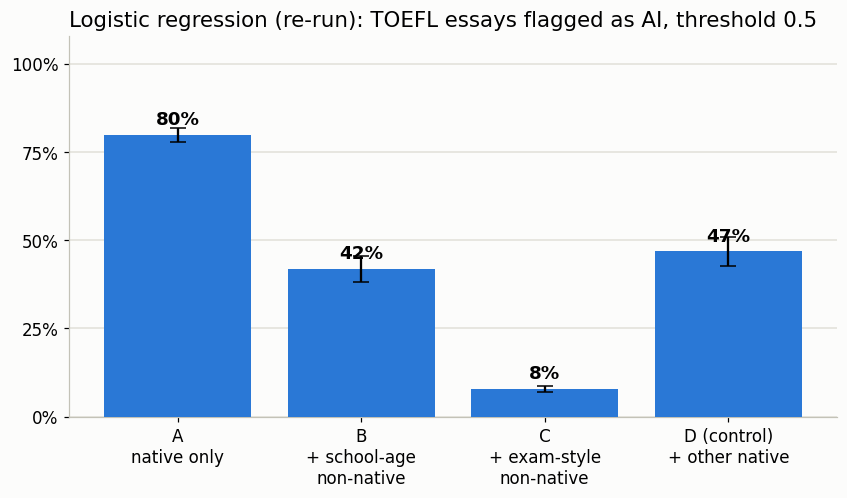

In [8]:
import matplotlib.pyplot as plt
P.setup()
fig, ax = plt.subplots(figsize=(9, 4.5))
m = main.groupby("arm").FP_TOEFL.agg(["mean", "std"]).fillna(0) * 100
ax.bar(range(4), m["mean"], yerr=m["std"], color=P.C_LR, capsize=5, zorder=3)
for i, v in enumerate(m["mean"]): ax.text(i, v + 3, f"{v:.0f}%", ha="center", fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels([P.ARM_LABELS[a] for a in "ABCD"]); P._pct_axis(ax, 108)
ax.set_title("Logistic regression (re-run): TOEFL essays flagged as AI, threshold 0.5", loc="left")
plt.show()

## 6. Precision, recall and F1 on the Liang test set
394 human essays (TOEFL 91, Hewlett 88, college essays 70, CS224N 145) and 352 GPT-3 essays; AI is the positive class;
threshold 0.5. *Precision*: of the essays flagged as AI, the share that really are AI. *Recall*: of the AI essays,
the share that is caught. *F1* combines the two (harmonic mean). Formulas copied from `a40/prf1.py`.

In [9]:
prf_cols = ["accuracy", "precision", "recall", "f1"]
prf_summ = main.groupby("arm")[prf_cols].agg(["mean", "std"])
display(prf_summ.round(3))

accuracy        precision        recall            f1       
        mean    std      mean    std   mean    std   mean    std
arm                                                             
A      0.628  0.006     0.560  0.004  0.994  0.000  0.716  0.003
B      0.682  0.007     0.600  0.006  0.977  0.005  0.743  0.003
C      0.773  0.003     0.689  0.004  0.948  0.002  0.798  0.002
D      0.782  0.021     0.715  0.012  0.894  0.052  0.794  0.025

## 7. Comparison with the archived numbers of the original run
Archived values come from `data/results/` (computed on the A40 server in November 2026). Tolerances: 3 percentage
points for false-flag rates (one TOEFL essay is 1.1 points), 0.02 for precision / recall / F1 / AUC.

In [10]:
cmp_rows = []
if MODE == "SMOKE":
    print("SKIPPED in SMOKE mode: the SMOKE models are trained on 400 essays, so their numbers are not comparable.")
else:
    old_cm = D.load_result("model_comparison_all").set_index(["model", "arm"])
    old_prf = D.load_result("prf1_summary"); old_prf = old_prf[old_prf.model == "LR"].set_index("arm")
    old_fu = D.load_result("followup_runs").groupby("arm")
    for arm in "ABCD":
        mm = main[main.arm == arm]
        cmp_rows += [
            M.compare(f"arm {arm}: TOEFL flagged at 0.5", mm.FP_TOEFL.mean(), old_cm.loc[("LR", arm), "FP_TOEFL"], 0.03),
            M.compare(f"arm {arm}: familiar native (Hewlett) flagged", mm.FP_Hewlett.mean(), old_cm.loc[("LR", arm), "FP_Hewlett"], 0.03),
            M.compare(f"arm {arm}: unfamiliar native flagged", mm.FP_nativeOOD_mean.mean(), old_cm.loc[("LR", arm), "FP_nativeOOD_mean"], 0.03),
            M.compare(f"arm {arm}: TOEFL flagged at 90%-detection threshold", mm.flag90_TOEFL.mean(), old_fu.P1_toefl_flag90.mean()[arm], 0.03),
            M.compare(f"arm {arm}: bias AUC TOEFL vs Hewlett", mm.bias_TOEFLvsHewlett.mean(), old_fu.bias_auc_vs_hewlett.mean()[arm], 0.02),
            M.compare(f"arm {arm}: precision (Liang set)", mm.precision.mean(), old_prf.loc[arm, "precision__mean"], 0.02),
            M.compare(f"arm {arm}: recall (Liang set)", mm.recall.mean(), old_prf.loc[arm, "recall__mean"], 0.02),
            M.compare(f"arm {arm}: F1 (Liang set)", mm.f1.mean(), old_prf.loc[arm, "f1__mean"], 0.02)]
    # the rounded numbers quoted in the presentation
    quoted = {"A": (0.80, 0.72), "B": (0.42, 0.74), "C": (0.08, 0.80), "D": (0.47, 0.79)}
    for arm, (tq, fq) in quoted.items():
        mm = main[main.arm == arm]
        cmp_rows += [M.compare(f"arm {arm}: TOEFL flagged vs quoted {tq:.0%}", mm.FP_TOEFL.mean(), tq, 0.03),
                     M.compare(f"arm {arm}: F1 vs quoted {fq:.2f}", mm.f1.mean(), fq, 0.02)]
    cmp = pd.DataFrame(cmp_rows)
    with pd.option_context("display.max_rows", 100):
        display(cmp.round(4))
    for r in cmp.itertuples():
        print(f"{r.result}  {r.check}: re-run {r.recomputed:.3f} vs reference {r.archived:.3f} (tolerance {r.tolerance})")
    print(f"\nCOMPARISON SUMMARY: {(cmp.result == 'PASS').sum()} PASS, {(cmp.result == 'FAIL').sum()} FAIL")

,check,recomputed,archived,tolerance,result
0,arm A: TOEFL flagged at 0.5,0.7978,0.7978,0.03,PASS
1,arm A: familiar native (Hewlett) flagged,0.0205,0.0205,0.03,PASS
2,arm A: unfamiliar native flagged,0.8493,0.8507,0.03,PASS
3,arm A: TOEFL flagged at 90%-detection threshold,0.8066,0.8066,0.03,PASS
4,arm A: bias AUC TOEFL vs Hewlett,0.9874,0.9871,0.02,PASS
5,arm A: precision (Liang set),0.5597,0.5598,0.02,PASS
6,arm A: recall (Liang set),0.9943,0.9949,0.02,PASS
7,arm A: F1 (Liang set),0.7162,0.7165,0.02,PASS
8,arm B: TOEFL flagged at 0.5,0.4176,0.4220,0.03,PASS
9,arm B: familiar native (Hewlett) flagged,0.0114,0.0114,0.03,PASS


PASS  arm A: TOEFL flagged at 0.5: re-run 0.798 vs reference 0.798 (tolerance 0.03)
PASS  arm A: familiar native (Hewlett) flagged: re-run 0.020 vs reference 0.020 (tolerance 0.03)
PASS  arm A: unfamiliar native flagged: re-run 0.849 vs reference 0.851 (tolerance 0.03)
PASS  arm A: TOEFL flagged at 90%-detection threshold: re-run 0.807 vs reference 0.807 (tolerance 0.03)
PASS  arm A: bias AUC TOEFL vs Hewlett: re-run 0.987 vs reference 0.987 (tolerance 0.02)
PASS  arm A: precision (Liang set): re-run 0.560 vs reference 0.560 (tolerance 0.02)
PASS  arm A: recall (Liang set): re-run 0.994 vs reference 0.995 (tolerance 0.02)
PASS  arm A: F1 (Liang set): re-run 0.716 vs reference 0.716 (tolerance 0.02)
PASS  arm B: TOEFL flagged at 0.5: re-run 0.418 vs reference 0.422 (tolerance 0.03)
PASS  arm B: familiar native (Hewlett) flagged: re-run 0.011 vs reference 0.011 (tolerance 0.03)
PASS  arm B: unfamiliar native flagged: re-run 0.785 vs reference 0.786 (tolerance 0.03)
PASS  arm B: TOEFL fla

## 8. Paired test on the same 91 TOEFL essays
Same seed, same essays, two training sets: does arm X flag fewer TOEFL essays than arm Y? *diff* = X minus Y
(negative = X flags fewer). *p* is the exact McNemar test (are the essays flagged by only one of the two arms split
evenly?). 95% interval from 1,000 bootstrap resamples of the essays. Threshold: the 90%-detection threshold, as
pre-registered. Same computation and random-number order as `a40/followup_metrics.py`.

In [11]:
if MODE == "SMOKE":
    print("SKIPPED in SMOKE mode (needs all four arms with the full test set).")
else:
    rng = np.random.default_rng(0)
    flags = {}
    for (arm, seed, n), p in preds.items():
        if n != 4000: continue
        pp = M.drop_train_exams(p, train_ids)
        flags[(arm, seed)] = (pp[pp.corpus == M.TOEFL].set_index("essay_id").score >= M.thr_tpr90(pp)).astype(int)
    pair = pd.DataFrame([dict(pair=f"{x}-{y}", seed=s, **M.paired_flags(flags[(x, s)], flags[(y, s)], rng=rng))
                         for x, y in (("C", "A"), ("C", "D"), ("B", "A")) for s in SEEDS])
    old = D.load_result("followup_paired")
    pair = pair.merge(old[["pair", "seed", "diff", "p"]].rename(columns={"diff": "archived_diff", "p": "archived_p"}), on=["pair", "seed"])
    for c in ("p", "archived_p"): pair[c] = pair[c].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
    display(pair[["pair", "seed", "rate_x", "rate_y", "diff", "lo", "hi", "p", "archived_diff", "archived_p"]].round(3))
    print("Small differences from the archived columns come from the re-trained models (section 4), not from the test.")

,pair,seed,rate_x,rate_y,diff,lo,hi,p,archived_diff,archived_p
0,C-A,0,0.088,0.802,-0.714,-0.802,-0.615,<0.001,-0.714,<0.001
1,C-A,1,0.088,0.824,-0.736,-0.824,-0.637,<0.001,-0.736,<0.001
2,C-A,2,0.066,0.780,-0.714,-0.802,-0.615,<0.001,-0.714,<0.001
3,C-A,3,0.077,0.846,-0.769,-0.846,-0.681,<0.001,-0.769,<0.001
4,C-A,4,0.077,0.780,-0.703,-0.791,-0.604,<0.001,-0.703,<0.001
5,C-D,0,0.088,0.484,-0.396,-0.505,-0.286,<0.001,-0.396,<0.001
6,C-D,1,0.088,0.473,-0.385,-0.495,-0.286,<0.001,-0.407,<0.001
7,C-D,2,0.066,0.505,-0.440,-0.549,-0.330,<0.001,-0.429,<0.001
8,C-D,3,0.077,0.429,-0.352,-0.451,-0.242,<0.001,-0.352,<0.001
9,C-D,4,0.077,0.527,-0.451,-0.560,-0.341,<0.001,-0.451,<0.001


Small differences from the archived columns come from the re-trained models (section 4), not from the test.


## 9. Which words push an essay towards "AI"?
A strength of logistic regression: each word has one weight we can read. Below, the 12 words or word pairs with the
largest weights towards "AI" for arm A and arm C (seed 0). Long, formal connective phrases tend to dominate.

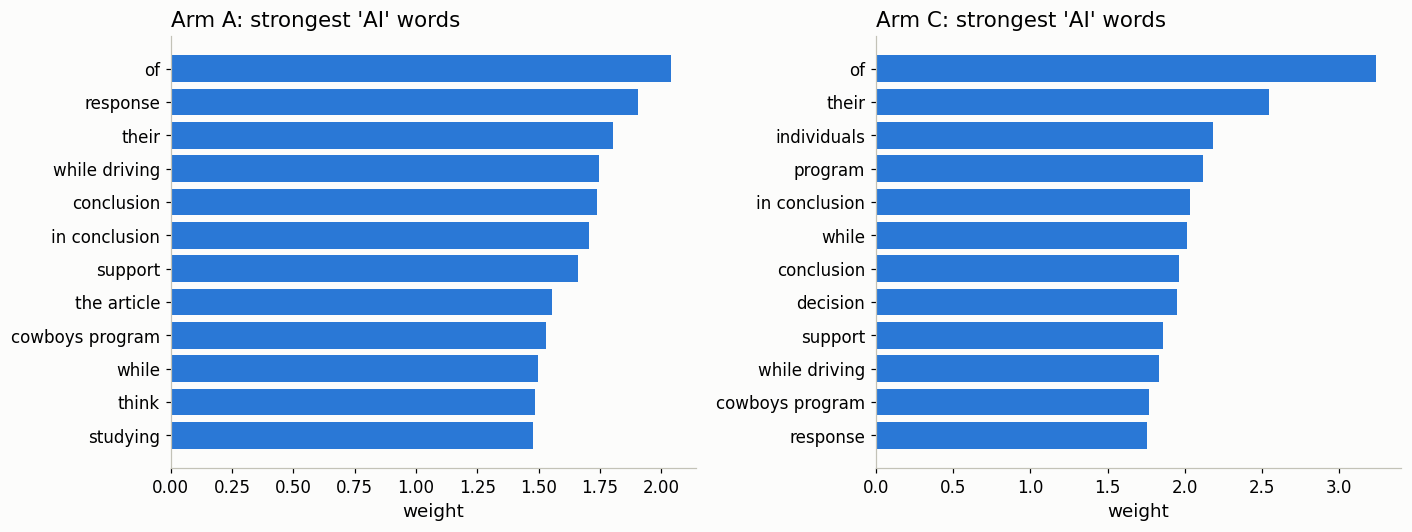

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, arm in zip(axes, "AC"):
    clf = models[arm]; vocab = clf.named_steps["tfidf"].get_feature_names_out(); w = clf.named_steps["lr"].coef_[0]
    top = np.argsort(w)[-12:]
    ax.barh(range(12), w[top], color=P.C_LR); ax.set_yticks(range(12)); ax.set_yticklabels(vocab[top])
    ax.set_title(f"Arm {arm}: strongest 'AI' words", loc="left"); ax.set_xlabel("weight")
fig.tight_layout(); plt.show()

## 10. Learning curve (FULL mode only)
Does more training data help? Arms A and B were also trained with 1,000 and 2,000 essays per class.

In [13]:
if MODE != "FULL":
    print("SKIPPED (runs only in FULL mode).")
else:
    agg = D.load_result("metrics_agg"); agg = agg[agg.model == "LR"].assign(n=lambda d: d.n.astype(int))
    lc = runs[runs.arm.isin(["A", "B"])].groupby(["arm", "n"]).FP_TOEFL.mean().rename("TOEFL flagged (re-run)").reset_index()
    lc = lc.merge(agg[["arm", "n", "rate_t05_TOEFL_real_91__mean"]].rename(columns={"rate_t05_TOEFL_real_91__mean": "archived"}), on=["arm", "n"])
    display(lc.round(3))
    for r in lc.itertuples():
        c = M.compare(f"arm {r.arm}, {r.n} per class: TOEFL flagged", r[3], r.archived, 0.03)
        print(f"{c['result']}  {c['check']}: re-run {c['recomputed']:.3f} vs archived {c['archived']:.3f}")

SKIPPED (runs only in FULL mode).


In [14]:
print(f"Notebook finished in {time.time() - T0:.0f} s (mode {MODE}, {len(RUNS)} training runs).")

Notebook finished in 103 s (mode FAST, 20 training runs).
